# Part 1. 데이터 추출

## 0. 환경 검증

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.14.7
가상환경 경로: c:\Workspace\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


## 1. 임포트 라이브러리

In [2]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

c:\Workspace\multimodal-rag\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


임포트 완료


## 2. 경로 설정

In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# pdf파일의 이름 지정 및 경로 지정
fname = "2Q26-MOVEX-IR-BOOK.pdf"

fpath = str(PROJECT_ROOT / "data") + os.sep

print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더    :", fpath)
print("PDF 존재 여부:", os.path.exists(fpath + fname))

프로젝트 루트: c:\Workspace\multimodal-rag
PDF 폴더    : c:\Workspace\multimodal-rag\data\
PDF 존재 여부: True


## 3. 추출 함수 만들기

In [4]:
def extract_pdf_elements(fpath, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출
    path: 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=fpath + fname,                            # 파일 이름과 위치 합쳐서 지정
        strategy="hi_res",                                # 추출 전략 선택
        extract_image_block_types=["Image"],              # 이미지를 추출
        extract_image_block_output_dir=fpath + "figures",  # data/figures 에 저장
        infer_table_structure=True,                       # 표 구조를 추론
        chunking_strategy="by_title",                     # 타이틀 기준으로 텍스트 분할
        max_characters=4000,                              # 최대 4000자로 블록 제한
        new_after_n_chars=3800,                           # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,                  # 2000자 이하는 결합
        languages=["kor", "eng"],                         # 한글 PDF라서 OCR 언어 지정
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 4. 요소 분류 함수 만들기

In [5]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.
    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        name = type(element).__name__              # 종류 이름만 꺼내기
        if name in ("Table", "TableChunk"):         # 표 (쪼개진 표 포함)
            tables.append(str(element))
        elif name == "CompositeElement":            # 텍스트 덩어리
            texts.append(str(element))

    return texts, tables

print("categorize_elements 정의 완료")

categorize_elements 정의 완료


## 5. 추출 실행

In [6]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 - {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3503.74it/s]


추출 완료 - 79.2초 소요
추출된 전체 요소 수: 5


In [7]:
# 변수 이름을 tables → unstructured_tables 로 바꾼 이유:
# 이 셀은 partition_pdf(unstructured)가 찾은 표만 센다(결과 0개). 5.2절에서 VLM이 만든 표를
# tables 에 담는데, 여기서도 tables 라는 이름을 쓰면 이 셀을 다시 실행하는 순간
# VLM 표가 빈 리스트로 덮어써진다. 이름을 분리해 "unstructured 0개 vs VLM 표"를 구분한다.
texts, unstructured_tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("unstructured 표 블록 수:", len(unstructured_tables))   # 0 → hi_res가 표를 못 찾음

텍스트 블록 수: 5
unstructured 표 블록 수: 0


## 5.1 추출된 요소에 표가 안들어간걸 확인

 확인 시 표가 5, 8, 14, 20, 21페이지에 있음을 확인했어도 추출이 안된 것을 눈으로 확인함 아래 코드로 다시 확인

In [8]:
import pdfplumber

with pdfplumber.open(fpath + fname) as pdf:
    page = pdf.pages[4]    # 5페이지
    text = page.extract_text()
    for key in ["1,766", "1,753", "영업이익", "△73.5%", "3,818"]:
        print(f"{key:10s} 포함:", key in text)

    # tables → plumber_tables 로 바꾼 이유: 이 셀의 tables 가 나중에 쓸 최종 tables 와
    # 이름이 같아 서로 덮어쓰는 것을 막기 위해 pdfplumber 결과임을 이름에 드러냄
    plumber_tables = page.extract_tables()
    print("선 기준 표 개수:", len(plumber_tables))

    plumber_tables2 = page.extract_tables({"vertical_strategy": "text", "horizontal_strategy": "text"})
    print("글자 위치 기준 표 개수:", len(plumber_tables2))
    if plumber_tables2:
        for row in plumber_tables2[0][:6]:
            print(row)

1,766      포함: False
1,753      포함: False
영업이익       포함: True
△73.5%     포함: True
3,818      포함: False
선 기준 표 개수: 1
글자 위치 기준 표 개수: 1
['', '', '', '', '△0.7%']
['', '', '', '', '']
['물류자동화', '1,375 78%', '1,298', '74%', '△5.6%']
['', '', '', '', '']
['PSD', '265', '243', '14%', '△8.4%']
['', '', '', '', '']


### 왜 hi_res가 표를 못 잡았을까?

확인 안 된 것: hi_res가 왜 표를 못 잡았나

hi_res는 글자가 아니라 페이지를 사진으로 찍어서 AI 모델로 영역을 찾는 방식이에요. 원리상 글자가 없어도 표를 찾을 수 있어요. 그런데 Table이 0개였다면 가능한 이유는 이래요.

모델이 이 모양의 표에 익숙하지 않아서. 레이아웃 모델은 논문, 보고서, 신문 같은 문서로 학습된 모델이에요. 색 칸에 얇은 선, 큰 제목이 있는 슬라이드형 표는 학습 분포 밖일 수 있어요. 이 경우 표를 그림이나 텍스트로 분류해요.
표로 찾았어도 내용을 못 채워서. 표 영역을 찾은 뒤 셀 안의 글자는 PDF의 글자 목록에서 가져와요. 그 글자가 없으면 내용이 비거나 요소로 남지 않을 수 있어요.
다른 종류로 분류돼서. 표가 Image나 CompositeElement로 들어갔을 수 있어요.

## 5.2 그러면 어떻게 표를 잡게 할 것인가

방식 (3단계)
표가 있는 페이지를 이미지로 변환 함 (Poppler 사용)
VLM(gpt-4o-mini)이 이미지를 보고 마크다운 표로 옮겨 적도록 함
글자 목록이 아니라 화면에 보이는 숫자를 읽기 때문에 빠진 행도 채워도록 함
결과를 tables 리스트에 추가 함 (pkl 저장·요약 단계가 이 tables 를 사용)

In [9]:
import base64, io
from pdf2image import convert_from_path, pdfinfo_from_path
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

vlm = ChatOpenAI(model="gpt-4o-mini", temperature=0, max_tokens=3000)

prompt = """이 페이지의 모든 표를 마크다운 표로 옮겨 적으세요.
1. 표마다 열 머리글을 왼쪽부터 빠짐없이 적으세요. 병합된 머리글(예: '2025' 아래에 '1Q', '2Q')은 '2025 1Q', '2025 2Q'처럼 하위 열마다 풀어서 쓰세요. 연간 열과 분기 열이 함께 있으면 서로 구분되게 쓰세요.
2. 모든 행이 머리글과 같은 수의 값을 갖게 하세요. 열을 건너뛰거나 합치지 마세요.
3. 행 이름은 보이는 그대로 쓰세요. 비슷한 단어로 바꾸지 마세요.
4. 제목과 단위를 표 앞에 적고, 숫자와 기호(△, %, -, 괄호)는 보이는 그대로 쓰세요. 없는 내용은 지어내지 마세요.
그래프, 사진, 아이콘, 목차, 장식은 표가 아닙니다. 표가 하나도 없으면 NO_TABLE 이라고만 답하세요."""

n_pages = pdfinfo_from_path(fpath + fname)["Pages"]
tables = []                                                    # 다시 실행해도 쌓이지 않게 초기화

for p in range(1, n_pages + 1):
    img = convert_from_path(fpath + fname, dpi=200, first_page=p, last_page=p)[0]
    buf = io.BytesIO()
    img.save(buf, format="JPEG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    msg = HumanMessage(content=[
        {"type": "text", "text": prompt},
        {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{b64}"}},
    ])
    result = vlm.invoke([msg]).content.strip()
    result = result.replace("```markdown", "").replace("```", "").strip()   # 코드 블록 표시 제거

    found = not result.startswith("NO_TABLE")
    print(f"{p}페이지:", "표 발견" if found else "표 없음")
    if found:
        tables.append(f"[{p}페이지 표]\n{result}")

print("표 블록 수:", len(tables))

1페이지: 표 없음
2페이지: 표 없음
3페이지: 표 없음
4페이지: 표 없음
5페이지: 표 발견
6페이지: 표 없음
7페이지: 표 없음
8페이지: 표 발견
9페이지: 표 없음
10페이지: 표 없음
11페이지: 표 없음
12페이지: 표 없음
13페이지: 표 없음
14페이지: 표 없음
15페이지: 표 없음
16페이지: 표 없음
17페이지: 표 없음
18페이지: 표 없음
19페이지: 표 없음
20페이지: 표 발견
21페이지: 표 발견
표 블록 수: 4


## 5.3 VLM 표 개수와 8페이지 열 머리글 확인

In [10]:
# 예전 줄 "tables = vlm_tables" 를 지운 이유:
# 5.2절 셀이 개선된 프롬프트로 바뀌면서 VLM 결과를 바로 tables 에 담는다. 그 줄을 남겨 두면
# 새 커널에서는 vlm_tables 가 없어 NameError, 기존 커널에서는 옛 표가 새 표를 덮어써 개선이 사라진다.
# 대신 개수와, 문제 A(병합 머리글)였던 8페이지 손익계산서의 열이 풀려서 나왔는지 확인한다.
print("VLM 표 블록 수:", len(tables))
for t in tables:
    if t.startswith("[8페이지"):
        print(t[:1500])

VLM 표 블록 수: 4
[8페이지 표]
# 4. 요약 연결재무제표
(단위: 억원)

## 연결 재무상태표

| 항목               | 2024  | 2025  | 2026  |
|--------------------|-------|-------|-------|
| 유동자산           | 2,197 | 1,919 | 2,019 |
| 현금및현금성자산   | 586   | 361   | 370   |
| 매출채권           | 655   | 607   | 832   |
| 비유동자산         | 791   | 915   | 1,413 |
| 자산총계           | 2,989 | 2,834 | 3,433 |
| 유동부채           | 1,102 | 1,078 | 1,405 |
| 매입채무           | 419   | 230   | 315   |
| 비유동부채         | 166   | 154   | 360   |
| 부채총계           | 1,267 | 1,231 | 1,765 |
| 자본금             | 118   | 118   | 118   |
| 자본총계           | 1,721 | 1,603 | 1,668 |

## 연결 손익계산서

| 항목               | 2024  | 2025  1Q | 2025 2Q | 2026 1Q | 2026 2Q |
|--------------------|-------|----------|----------|----------|----------|
| 매출액             | 3,414 | 3,939    | 777      | 989      | 750      | 1,004    |
| 매출원가           | 2,779 | 3,229    | 610      | 829      | 649      | 830      |
| 매출총이익         | 635   | 710      | 167      | 159    

## 6. 어떤 요소들이 나왔는지 집계

In [11]:
from collections import Counter

type_counts = Counter(type(el).__name__ for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:15s}: {count}개")


CompositeElement: 5개


## 7. 추출된 이미지 확인

In [12]:
figures_dir = Path(fpath) / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"   {f.name}   ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")

추출된 이미지: 113개

   figure-1-1.jpg   (3 KB)
   figure-1-2.jpg   (131 KB)
   figure-1-3.jpg   (0 KB)
   figure-10-28.jpg   (4 KB)
   figure-11-29.jpg   (3 KB)
   figure-11-30.jpg   (9 KB)
   figure-11-31.jpg   (7 KB)
   figure-11-32.jpg   (11 KB)
   figure-11-33.jpg   (11 KB)
   figure-11-34.jpg   (12 KB)


## 8. 텍스트 분할

In [13]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=400,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 5
분할 후 블록 수: 8
전체 글자 수  : 9998


## 9. 분할 결과 비교

In [14]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
HYUNDAI MOVEX

Investor Relations 2026 2026년 2분기 경영실적

DISCLAIMER

본 자료는 투자자들을 대상으로 정보제공 목적으로 현대무벡스㈜에 의해 작성되었으며 이의 반출, 복사 또는 타인에 대한 재배포는 금지됨을 알려드리는 바입니다. 본 자료에 포함된 재무정보는 외부감사인의 회계감사가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료로서, 추후 그 내용 중 일부가 달라질 수 있음을 유의하시기 바랍니다. 또한, 본 자료는 미래에 대한 예측정보를 포함하고 있습니다. 이러한 예측 정

[분할 texts_2k_token[0]] 앞 300자
HYUNDAI MOVEX

Investor Relations 2026 2026년 2분기 경영실적

DISCLAIMER

본 자료는 투자자들을 대상으로 정보제공 목적으로 현대무벡스㈜에 의해 작성되었으며 이의 반출, 복사 또는 타인에 대한 재배포는 금지됨을 알려드리는 바입니다. 본 자료에 포함된 재무정보는 외부감사인의 회계감사가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료로서, 추후 그 내용 중 일부가 달라질 수 있음을 유의하시기 바랍니다. 또한, 본 자료는 미래에 대한 예측정보를 포함하고 있습니다. 이러한 예측 정


## 10. 이후 텍스트·표·이미지를 검색 가능한 요약문으로 만들기 위해 pkl파일 생성

In [15]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\Workspace\multimodal-rag\data\processed\extracted.pkl


# Part 2. 요약생성

## 0. API 키 불러오기

In [16]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        위에 PROJECT_ROOT를 정했으니 생략

# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(dotenv_path=PROJECT_ROOT / ".env")

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
getenv = os.getenv
openai_api_key = getenv("OPENAI_API_KEY")

# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"환경변수 OPENAI_API_KEY: {openai_api_key[:7]}...{openai_api_key[-4:]}")


환경변수 OPENAI_API_KEY: sk-proj...Vq0A


In [17]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인
from openai import OpenAI, AuthenticationError
try:
    client = OpenAI(api_key=openai_api_key)
    client.models.list()
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 유효하지 않습니다. .env 파일을 확인하세요.")


## 1. extracted.pkl 파일 복원

In [18]:
# pkl_path 경로설정
pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f:
    data = pickle.load(f)

# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data.get("texts", [])
tables = data.get("tables", [])
texts_2k_token = data.get("texts_2k_token", [])

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"Number of texts: {len(texts)}")
print(f"Number of tables: {len(tables)}")
print(f"Number of texts (2k tokens): {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "invest" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures"
if figures_dir.exists():
    print(f"Figures directory exists: {figures_dir}")


Number of texts: 5
Number of tables: 4
Number of texts (2k tokens): 8
Figures directory exists: c:\Workspace\multimodal-rag\data\figures


## 1.1 표도 잘 나오는지 다시 확인

In [19]:
print(len(tables))
print(tables[0][:200] if tables else "비어 있음")

4
[5페이지 표]
# 1. ‘26년 2분기 경영 실적
(단위: 억원, %)

| 항목         | 2025 2Q25 YTD | 2025 비중 | 2026 2Q26 YTD | 2026 비중 | YoY     |
|--------------|----------------|-----------|----------------|-----------|-------


## 2. 요약 체인 만들기

In [20]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from typer import prompt

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.
def generate_text_summaries(texts, tables, summarize_texts=False):
    
#   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
#          내용: "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
#                 검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"

#   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.
    prompt_text_kor = "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 / 검색에 최적화된 간결한 요약 작성 / 절대 많이 요약하지 말 것 요약률 30% 이하 / 요약할 표 또는 텍스트: {element}"
    prompt = ChatPromptTemplate.from_template(prompt_text_kor)
#   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")
#   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.
#       요약을 위한 체인 = 입력포장 | 모델 | 출력파서
    summarize_chain = prompt | model | StrOutputParser()#   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.
    text_summaries = []
    table_summaries = []

#   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
#          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts and not summarize_texts:
        text_summaries = texts

#   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})
        
#   ⌨️ (8) text_summaries, table_summaries 를 반환합니다.
    return text_summaries, table_summaries

# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.
print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

In [21]:
import time
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"소요 시간: {time.time() - start:.2f} seconds")
print(f"텍스트 요약 수: {len(text_summaries)}")
print(f"표 요약 수: {len(table_summaries)}")


소요 시간: 27.68 seconds
텍스트 요약 수: 8
표 요약 수: 4


## 4. 요약 결과 확인

In [22]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("=" * 50)
print("원본 텍스트:")
print(texts_2k_token[0][:300])

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("=" * 50)
print("요약 텍스트:")
print(text_summaries[0])

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
original_length = len(texts_2k_token[0])
summary_length = len(text_summaries[0])
compression_rate = (1 - summary_length / original_length) * 100
print(f"원본 글자 수: {original_length}")
print(f"요약 글자 수: {summary_length}")
print(f"요약 비율(압축률): {compression_rate:.2f}%")


원본 텍스트:
HYUNDAI MOVEX

Investor Relations 2026 2026년 2분기 경영실적

DISCLAIMER

본 자료는 투자자들을 대상으로 정보제공 목적으로 현대무벡스㈜에 의해 작성되었으며 이의 반출, 복사 또는 타인에 대한 재배포는 금지됨을 알려드리는 바입니다. 본 자료에 포함된 재무정보는 외부감사인의 회계감사가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료로서, 추후 그 내용 중 일부가 달라질 수 있음을 유의하시기 바랍니다. 또한, 본 자료는 미래에 대한 예측정보를 포함하고 있습니다. 이러한 예측 정
요약 텍스트:
**HYUNDAI MOVEX 2026년 2분기 경영실적 요약**

본 자료는 현대무벡스㈜가 투자자들에게 제공하기 위해 작성된 것으로, 외부감사 완료 전의 재무정보를 포함하고 있습니다. 자료의 내용은 향후 변경될 수 있으며, 미래 예측정보는 다양한 위험 요소와 시장 상황에 따라 영향을 받을 수 있습니다. 이 자료는 투자 판단을 위한 참고자료로, 현대무벡스㈜ 및 임직원은 내용에 대한 보증이나 책임을 지지 않습니다. 자료의 복사 및 재배포는 금지됩니다.
원본 글자 수: 804
요약 글자 수: 252
요약 비율(압축률): 68.66%


## 5. table_summaries가 비어 있다면?

In [23]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.
if table_summaries:
    # print(f"표가 {len(table_summaries)}개 있습니다.")
    # print("첫 번째 표 요약:")
    # print(table_summaries[0])
    # for i, summary in enumerate(table_summaries[:3]):
    #     print("=" * 50)
    #     print(f"표 요약 {i+1}:")
    #     print("=" * 50)
    #     print(summary)
    #     print()
    for i, summary in enumerate(zip(tables[:2], table_summaries[:2])):
        print("=" * 50)
        print(f"표 {i+1}:")
        print("=" * 50)
        print("원본 표:")
        print(summary[0])
        print("요약 표:")
        print(summary[1])
        print()

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
else:
    print("table_summaries가 비어있습니다. 원인: (1) tables이 비어있거나 (2) 요약 과정에서 오류가 발생했을 수 있습니다.")


표 1:
원본 표:
[5페이지 표]
# 1. ‘26년 2분기 경영 실적
(단위: 억원, %)

| 항목         | 2025 2Q25 YTD | 2025 비중 | 2026 2Q26 YTD | 2026 비중 | YoY     |
|--------------|----------------|-----------|----------------|-----------|---------|
| 매출액       | 1,766          | 100%      | 1,753          | 100%      | △0.7%   |
| 물류자동화   | 1,375          | 78%       | 1,298          | 74%       | △5.6%   |
| PSD          | 265            | 15%       | 243            | 14%       | △8.4%   |
| IT           | 125            | 7%        | 122            | 7%        | △2.7%   |
| 기타         | -              | -         | 90             | 5%        | -       |
| 영업이익     | 96             | -         | 26             | -         | △73.5%  |
| 영업이익률(%)| 5.5%           | -         | 1.5%           | -         | -       |
| 당기순이익   | 51             | -         | 112            | -         | 119.2%  |
| 수주 실적    | 1,677          | -         | 1,792          | -         | 6.8%    |
| 수주 잔고    | 4,215          | -         | 3,818 

## 6. 이미지를 Base64로 포장하기

In [24]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.
image_files = sorted(                                #3. 이름순으로 정렬해서 리스트로 반환
    f for f in figures_dir.iterdir()                 #1. 폴더안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"] #2. 확장자가 이미지인 것만
)

# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.

sample_b64 = encode_image(image_files[0])

print(f"첫 번째 이미지 파일 이름: {image_files[0].name}")
print(f"인코딩된 문자열 길이: {len(sample_b64)}자")
print(f"인코딩된 문자열 앞 100자: {sample_b64[:100]}")



첫 번째 이미지 파일 이름: figure-1-1.jpg
인코딩된 문자열 길이: 5288자
인코딩된 문자열 앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


## 7. 이미지 요약 함수 만들기

In [25]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):
    #   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

    #   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
    #          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    message = HumanMessage(
        content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}}
        ]
    )
    response = chat.invoke([message])

#   ⌨️ (3) 응답의 .content 를 반환합니다.
    return response.content


# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = (
    "You are an assistant that summarizes images for search purposes. "
    "The summary should be concise and optimized for embedding in search. "
    "Please provide a summary of the image content. "
    "Write the summary in Korean (Hangul)."
)

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
image_summary = image_summarize(sample_b64, test_prompt)
print("=" * 50)
print("이미지 요약:")
print(image_summary)


이미지 요약:
현대무벡스 로고 이미지. 삼각형과 한글 텍스트로 구성됨.


## 8. 폴더 내 전체 이미지 요약

In [26]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path):

#   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []
    image_summaries = []

#   ⌨️ (2) 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
#   프롬프트를 바꾼 이유 (8.1 문제 B):
#     - 7페이지 수주 도넛을 "예산이 분배된 비율"이라고 추측해서 써서, "수주" 질문과 연결되지 않았다
#       → 제목을 그대로 적고, 차트는 항목명·수치를 빠짐없이 적고, 용도를 추측하지 않게 했다.
#     - 목차 이미지(4번 반복)의 요약이 검색 상위를 차지했다
#       → 목차·표지·로고·아이콘은 SKIP 으로 답하게 하고, SKIP 은 색인에서 뺀다.
    prompt_kor = (
        "이 이미지는 기업 IR 자료(PDF)에서 잘라낸 그림입니다. 검색에 쓰일 요약을 한국어로 작성하세요.\n"
        "1. 이미지 안에 제목이나 머리글이 있으면 그대로 적으세요.\n"
        "2. 차트(막대, 도넛, 선)라면 항목명, 수치, 단위, 기간을 빠짐없이 적으세요.\n"
        "3. 이미지에 보이지 않는 내용이나 용도는 추측하지 마세요.\n"
        "4. 목차, 표지, 로고, 아이콘, 배경·장식 사진처럼 수치나 사실 정보가 없는 이미지는 SKIP 이라고만 답하세요."
    )

#   작은 이미지를 API에 보내기 전에 거르는 이유:
#   figures 의 113개 중 다수가 1~4KB 로고·아이콘이라 요약해도 정보가 없고, 이미지마다 API 호출 비용이 든다.
#   가로나 세로가 MIN_SIDE 픽셀보다 작으면 요약하지 않는다.
    from PIL import Image as PILImage
    MIN_SIDE = 150
    kept_files = []                 # 색인에 들어간 이미지 파일 이름 (요약·원본과 순서가 같음)
    n_small, n_skip = 0, 0

#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → (작은 이미지 제외) → encode_image → image_summarize
#          → SKIP 이 아니면 원본과 요약을 같은 순서로 리스트에 추가
#          (SKIP 이면 둘 다 추가하지 않아야 요약과 원본의 짝이 어긋나지 않는다)
    for file_name in sorted(os.listdir(path)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            full_path = os.path.join(path, file_name)
            with PILImage.open(full_path) as im:
                if min(im.size) < MIN_SIDE:
                    n_small += 1
                    continue
            img_base64 = encode_image(full_path)
            summary = image_summarize(img_base64, prompt_kor).strip()
            if summary.upper().startswith("SKIP"):
                n_skip += 1
                continue
            img_base64_list.append(img_base64)
            image_summaries.append(summary)
            kept_files.append(file_name)

    print(f"작은 이미지 제외: {n_small}개 / SKIP 제외: {n_skip}개 / 색인 대상: {len(image_summaries)}개")

#   ⌨️ (4) img_base64_list, image_summaries, kept_files 를 반환합니다.
    return img_base64_list, image_summaries, kept_files

# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
start_time = time.time()
img_base64_list, image_summaries, kept_files = generate_img_summaries(str(figures_dir))
elapsed_time = time.time() - start_time
print(f"소요 시간: {elapsed_time:.2f} seconds")
print(f"요약된 이미지 수: {len(image_summaries)}")


작은 이미지 제외: 50개 / SKIP 제외: 57개 / 색인 대상: 6개
소요 시간: 414.07 seconds
요약된 이미지 수: 6


## 9. 요약 품질 검증

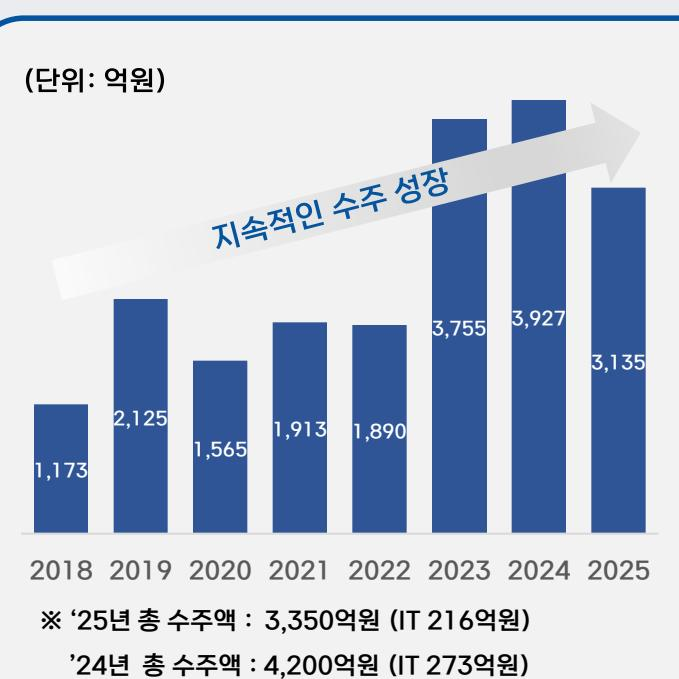

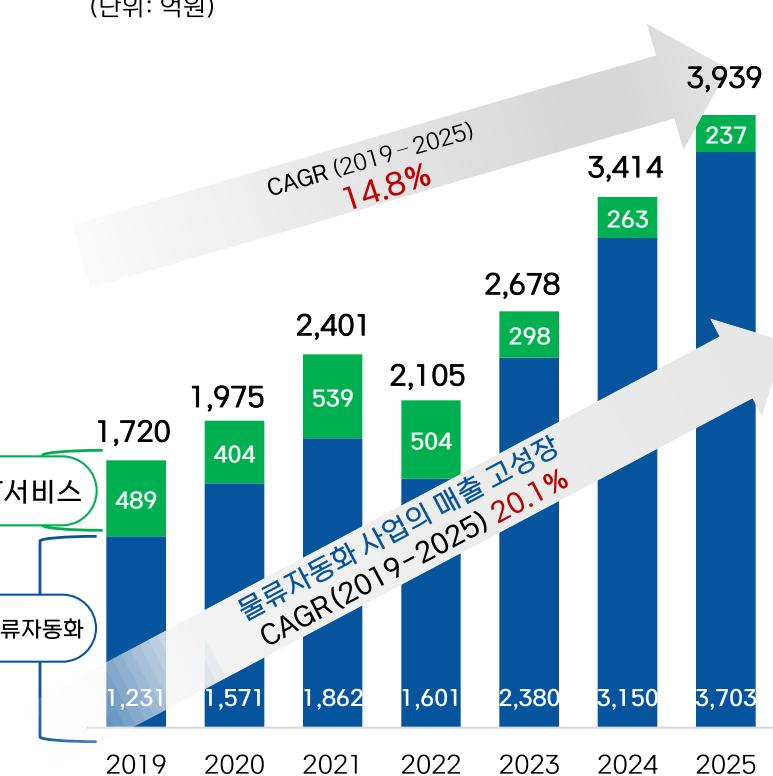

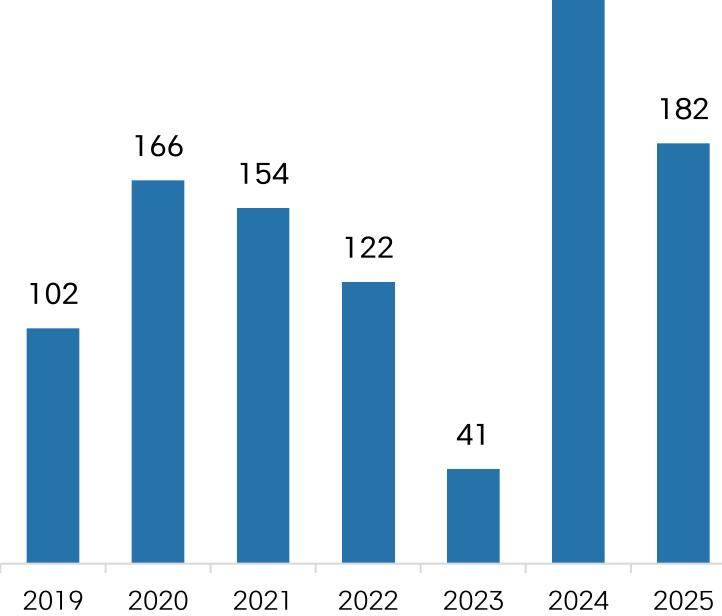

In [27]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
import IPython.display as display
import IPython.display as Image

# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.

# image_files(폴더 전체)가 아니라 kept_files(색인된 것)와 짝지은 이유:
# 8절에서 작은 이미지와 SKIP 이미지를 뺐기 때문에, 폴더 전체 목록과 요약 목록은 순서가 더 이상 맞지 않는다.
kept_paths = [figures_dir / name for name in kept_files]
for i, (img, summary) in enumerate(zip(kept_paths[:3], image_summaries[:3])):
    display.display(display.HTML(f"<hr><h3>Image {i+1}</h3>"))
    display.display(Image.Image(data=img, width=450))
    display.display(display.HTML(f"<p><strong>Summary:</strong> {summary}</p>"))

## 10. 토큰 사용량 측정

In [28]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens
input_tokens = sum(len(enc.encode(text)) for text in texts_2k_token)

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens
output_tokens = sum(len(enc.encode(summary)) for summary in text_summaries)

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
print(f"입력 토큰: {input_tokens:,}")
print(f"출력 토큰: {output_tokens:,}")
print(f"합계 토큰: {input_tokens + output_tokens:,}")
print(f"요약된 이미지 수: {len(image_summaries)}")



입력 토큰: 6,245
출력 토큰: 2,140
합계 토큰: 8,385
요약된 이미지 수: 6


## 11. 요약 데이터 저장

In [29]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list
with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump({
        "text_summaries": text_summaries,
        "table_summaries": table_summaries,
        "image_summaries": image_summaries,
        "img_base64_list": img_base64_list,
        "kept_files": kept_files,          # 어떤 이미지가 색인됐는지 추적용 (작은 이미지·SKIP 제외 후)
    }, f)

# ⌨️ 11-3. 저장 경로를 출력합니다.

print(f"요약 데이터가 {output_dir / 'summaries.pkl'}에 저장되었습니다.")


요약 데이터가 c:\Workspace\multimodal-rag\data\processed\summaries.pkl에 저장되었습니다.


# Part 3. 다중 벡터 검색기 + 최종 체인

## 0. 이전 단계 pkl 파일 복원

In [30]:
import os
import re
import time
import uuid
import pickle
from pathlib import Path

from dotenv import load_dotenv

load_dotenv(PROJECT_ROOT / ".env")

if not os.getenv("OPENAI_API_KEY"):
    raise ValueError("OpenAI API 키가 없습니다. .env 파일을 확인하세요.")

processed = PROJECT_ROOT / "data" / "processed"

# 4교시 결과
with open(processed / "extracted.pkl", "rb") as f:
    d1 = pickle.load(f)
texts, tables, texts_2k_token = d1["texts"], d1["tables"], d1["texts_2k_token"]

# 5~6교시 결과
with open(processed / "summaries.pkl", "rb") as f:
    d2 = pickle.load(f)
text_summaries = d2["text_summaries"]
table_summaries = d2["table_summaries"]
image_summaries = d2["image_summaries"]
img_base64_list = d2["img_base64_list"]

print("복원 완료")
print(f"  텍스트  원본 {len(texts_2k_token):3d}건 / 요약 {len(text_summaries):3d}건")
print(f"  표      원본 {len(tables):3d}건 / 요약 {len(table_summaries):3d}건")
print(f"  이미지  원본 {len(img_base64_list):3d}건 / 요약 {len(image_summaries):3d}건")

복원 완료
  텍스트  원본   8건 / 요약   8건
  표      원본   4건 / 요약   4건
  이미지  원본   6건 / 요약   6건


## 1. 검색기 만들기

In [31]:
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever #최신 langchain 깔아서 그에 맞게 수정
from langchain_classic.storage import InMemoryStore                        #최신 langchain 깔아서 그에 맞게 수정
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)

store = InMemoryStore()
id_key = "doc_id"

retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    docstore=store,
    id_key=id_key,
)

print("검색기 생성 완료")

검색기 생성 완료


## 2. 요약과 원본을 같은 ID로 짝짓기

In [32]:
from langchain_core.documents import Document as _Doc


def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        _Doc(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    # TODO 1: 요약본은 어디에 넣을까요? (vectorstore / docstore)
    retriever.vectorstore.add_documents(summary_docs)

    # TODO 2: 원본은 어디에 넣을까요?
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))


if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료")
print("  벡터 DB에 저장된 요약 수:", vectorstore._collection.count())

색인 완료
  벡터 DB에 저장된 요약 수: 18


## 3. 검색 테스트

In [33]:
# TODO 3: 그래프나 표를 봐야만 답할 수 있는 질문을 적으세요
query = "2분기 경영 실적 중 매출액이 YoY랑 비교했을 때 얼마나 증감했어?"

found = retriever.invoke(query)

print("검색된 원본 수:", len(found))
print()

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()

검색된 원본 수: 4

[0] 텍스트/표 — 길이 1,660자
    ‘26년 2분기 경영 실적 ‘26년 2분기 사업부별 실적 ‘26년 2분기 사업부별수주 현황 요약연결재무제표  02 Business Overview 사업소개 물류자동화 사업 PSD / IT서비스 사업 물류자동화R&D  ...

[1] 텍스트/표 — 길이 1,021자
    [5페이지 표] # 1. ‘26년 2분기 경영 실적 (단위: 억원, %)  | 항목         | 2025 2Q25 YTD | 2025 비중 | 2026 2Q26 YTD | 2026 비중 | YoY     | | ...

[2] 텍스트/표 — 길이 1,611자
    (단위:억원) 2024 2025 2Q26  소 현 대 무 벡스  연결 손익계산서  (단위:억원) 2024 3,939 182 113 2025 1Q 777 52 10 2Q 989 45 41 2026 1Q 2Q 750 1 ...

[3] 텍스트/표 — 길이 1,895자
    [21페이지 표] # 요약 연결재무제표 (단위: 억원)  | 유동자산 | 비유동자산 | 자산총계 | 유동부채 | 비유동부채 | 부채총계 | 자본금 | 자본잉여금 | 기타자본항목 | 이익잉여금 | 자본총계 | |--- ...



## 4. 검색 결과를 텍스트와 이미지로 분리

In [34]:
from langchain_core.documents import Document


def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
    b64_images = []
    texts_out = []

    for doc in docs:
        doc = doc.page_content if isinstance(doc, Document) else doc
        # Base64 문자열은 영문/숫자/+/= 만으로 길게 이어집니다
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", doc):
            b64_images.append(doc)
        else:
            texts_out.append(doc)

    return {"images": b64_images, "texts": texts_out}


# 앞서 검색한 결과로 동작 확인
split = split_image_text_types(found)
print("이미지:", len(split["images"]), "건")
print("텍스트:", len(split["texts"]), "건")

이미지: 0 건
텍스트: 4 건


## 5. 최종 멀티모달 체인 만들기

In [35]:
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI


def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    # 1) 이미지를 먼저 넣습니다 (모델이 그림을 먼저 보게)
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            # TODO 4: Base64 앞에 붙일 접두사를 완성하세요
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    # 2) 텍스트 컨텍스트와 질문을 넣습니다
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": (
            "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
            "자료에 없는 내용은 모른다고 답하세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n{formatted_texts}"
        ),
    })

    return [HumanMessage(content=messages)]


model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model                    
    | StrOutputParser()
)

print("최종 체인 조립 완료")

최종 체인 조립 완료


## 6. 질의 진행

In [36]:
start = time.time()
answer = chain.invoke(query)

print(f"답변 생성 — {time.time() - start:.1f}초\n")
print("Q:", query)
print("-" * 70)
print(answer)

답변 생성 — 1.2초

Q: 2분기 경영 실적 중 매출액이 YoY랑 비교했을 때 얼마나 증감했어?
----------------------------------------------------------------------
‘26년 2분기 경영 실적에서 매출액은 전년 대비 △0.7% 감소했습니다.


## 7. Before / After 비교

In [37]:
# 텍스트만 들어간 벡터 DB (= 11주차에 만든 것과 같은 구조)
text_only_store = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_only_store.add_texts(texts_2k_token)
text_only_retriever = text_only_store.as_retriever(search_kwargs={"k": 4})

text_only_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
    "자료에 없는 내용은 모른다고 답하세요.\n\n"
    "4줄로 답하세요.\n\n"
    "질문: {question}\n\n참고 텍스트:\n{context}"
)

text_only_chain = (
    {
        "context": text_only_retriever | (lambda docs: "\n".join(d.page_content for d in docs)),
        "question": RunnablePassthrough(),
    }
    | text_only_prompt
    | model
    | StrOutputParser()
)

print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [38]:
print("=" * 70)
print("질문:", query)
print("=" * 70)
print()

print("[BEFORE] 텍스트 전용 RAG")
print("-" * 70)
before = text_only_chain.invoke(query)
print(before)
print()

print("[AFTER] 멀티모달 RAG")
print("-" * 70)
after = chain.invoke(query)
print(after)
print()

print("=" * 70)
print("이 출력 전체를 캡처해 README.md에 넣으세요.")
print("=" * 70)

질문: 2분기 경영 실적 중 매출액이 YoY랑 비교했을 때 얼마나 증감했어?

[BEFORE] 텍스트 전용 RAG
----------------------------------------------------------------------
‘26년 2분기 누적 매출액은 전년 대비 Flat이라고 언급되어 있습니다. 즉, 매출액이 증가하거나 감소하지 않았다는 의미입니다. 구체적인 수치는 제공되지 않았습니다. 따라서 YoY 비교 시 매출액의 증감은 없었습니다.

[AFTER] 멀티모달 RAG
----------------------------------------------------------------------
‘26년 2분기 경영 실적에서 매출액은 전년 대비 △0.7% 감소했습니다.

이 출력 전체를 캡처해 README.md에 넣으세요.


## 8. 질의응답 6건 기록

In [ ]:
questions = [
    query,
    "26년 2분기 누적 영업이익은 얼마고, 전년 같은 기간보다 얼마나 줄었어?",
    "현대무벡스의 최대주주는 누구고 지분율은 몇 %야?",
    "26년 2분기 사업부별 수주현황 보고 어디가 제일 수주 많이 받았는지 알려줘",
    "26년 2분기 말 수주 잔고에서 물류자동화가 차지하는 비중은?",
    "2023년 수주 실적은 얼마였어?",
]


def is_table(text):
    """VLM으로 만든 표 원본은 '[N페이지 표]' 로 시작한다 (5.2절)."""
    return text.startswith("[") and "페이지 표]" in text.split("\n")[0]


rows = []
for q in questions:
    found_q = retriever.invoke(q)
    kinds = split_image_text_types(found_q)
    n_img = len(kinds["images"])
    n_tbl = sum(is_table(t) for t in kinds["texts"])
    n_txt = len(kinds["texts"]) - n_tbl
    answer = chain.invoke(q)
    rows.append({
        "질문": q,
        "답변": answer,
        "검색된 원본": f"이미지 {n_img} / 표 {n_tbl} / 텍스트 {n_txt}",
    })
    print("=" * 70)
    print("Q:", q)
    print("검색된 원본:", rows[-1]["검색된 원본"])
    print("A:", answer)
    print()

# README 에 붙일 수 있도록 마크다운 표로도 출력한다
print("| # | 질문 | 답변 | 검색된 원본 종류 |")
print("|---|---|---|---|")
for i, r in enumerate(rows, 1):
    ans = r["답변"].replace("\n", " ").replace("|", "/")
    print(f"| {i} | {r['질문']} | {ans} | {r['검색된 원본']} |")

Q: 2분기 경영 실적 중 매출액이 YoY랑 비교했을 때 얼마나 증감했어?
검색된 원본: 이미지 0 / 표 2 / 텍스트 2
A: ‘26년 2분기 경영 실적에서 매출액은 전년 대비 △0.7% 감소했습니다.

Q: 26년 2분기 누적 영업이익은 얼마고, 전년 같은 기간보다 얼마나 줄었어?
검색된 원본: 이미지 0 / 표 3 / 텍스트 1
A: ‘26년 2분기 누적 영업이익은 26억원이며, 전년 같은 기간인 ‘25년 2분기 누적 영업이익 96억원에 비해 70억원 줄었습니다.

Q: 현대무벡스의 최대주주는 누구고 지분율은 몇 %야?
검색된 원본: 이미지 1 / 표 0 / 텍스트 3
A: 현대무벡스의 최대주주는 현대 엘리베이터이며, 지분율은 48.9%입니다.

Q: 26년 2분기 사업부별 수주현황 보고 어디가 제일 수주 많이 받았는지 알려줘
검색된 원본: 이미지 0 / 표 1 / 텍스트 3
A: 자료에 따르면, 2026년 2분기 사업부별 수주현황에서 가장 많은 수주를 받은 사업부는 물류자동화입니다. 물류자동화 사업부는 전체 수주 실적의 47%를 차지하고 있습니다.

Q: 26년 2분기 말 수주 잔고에서 물류자동화가 차지하는 비중은?
검색된 원본: 이미지 1 / 표 1 / 텍스트 2
A: ‘26년 2분기 말 수주 잔고에서 물류자동화가 차지하는 비중은 47%입니다.

Q: 2023년 수주 실적은 얼마였어?
검색된 원본: 이미지 1 / 표 1 / 텍스트 2
A: 2023년 수주 실적은 3,755억 원입니다.

| # | 질문 | 답변 | 검색된 원본 종류 |
|---|---|---|---|
| 1 | 2분기 경영 실적 중 매출액이 YoY랑 비교했을 때 얼마나 증감했어? | ‘26년 2분기 경영 실적에서 매출액은 전년 대비 △0.7% 감소했습니다. | 이미지 0 / 표 2 / 텍스트 2 |
| 2 | 26년 2분기 누적 영업이익은 얼마고, 전년 같은 기간보다 얼마나 줄었어? | ‘26년 2분기 누적 영업이익은 26억원이며, 전년 같은 기간인 ‘25년 2분기 누적 영업이익 9